# Finite Differences Analysis
## <span style="color:dodgerblue; ">  Diffusion Equation 3D
<span style="color:dodgerblue; ">  $$\frac{\partial u}{\partial t} = D \nabla^2 u$$ </span>

# Explicit Scheme - Forward Time Centered Space (FTCS) 
## FTCS method is computationally inexpensive, but can become unstable.

<div align="center">
    <img src="Explicit_method-stencil.png" width="400">
</div> 
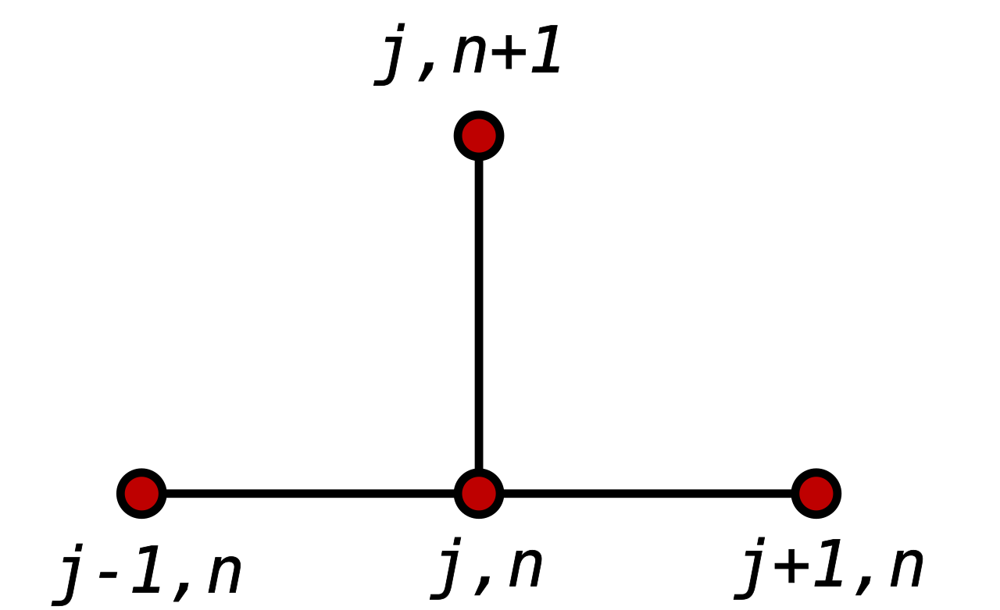
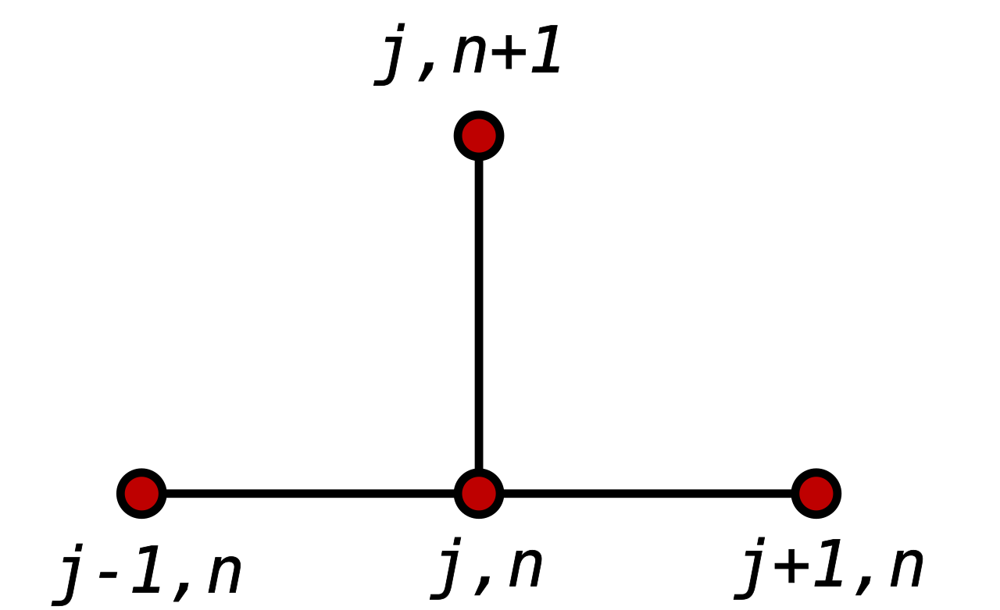
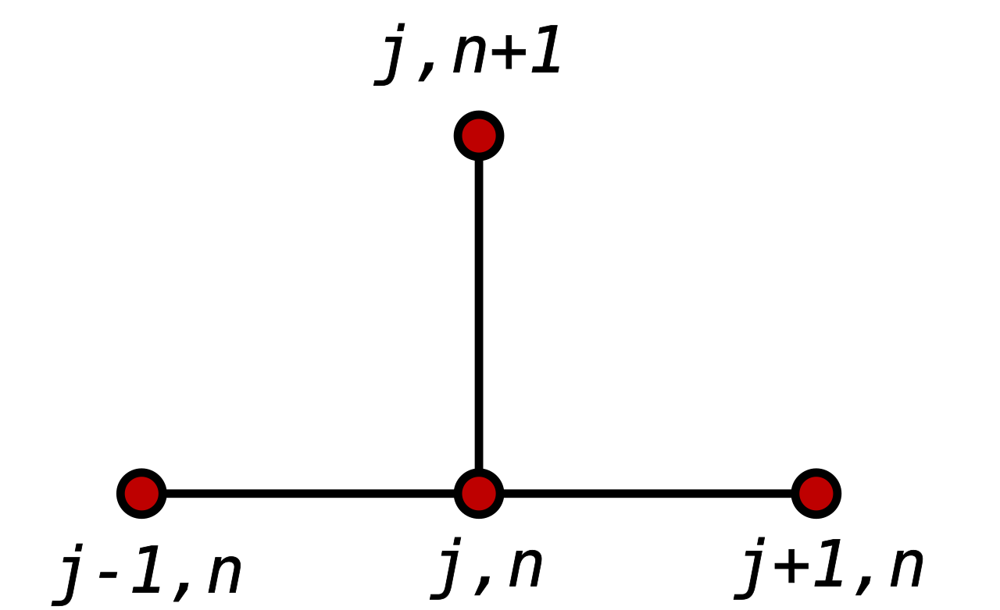
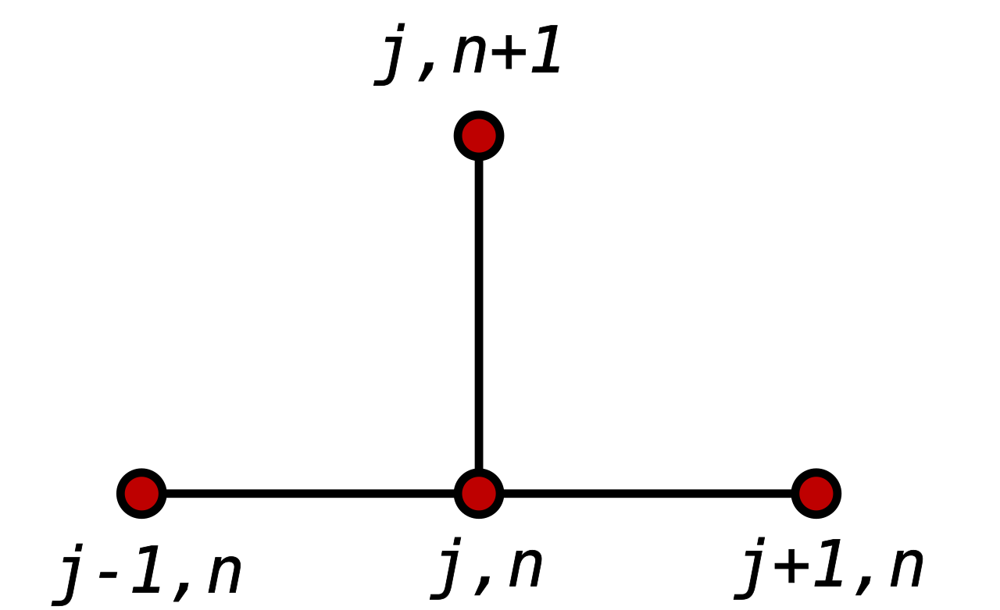
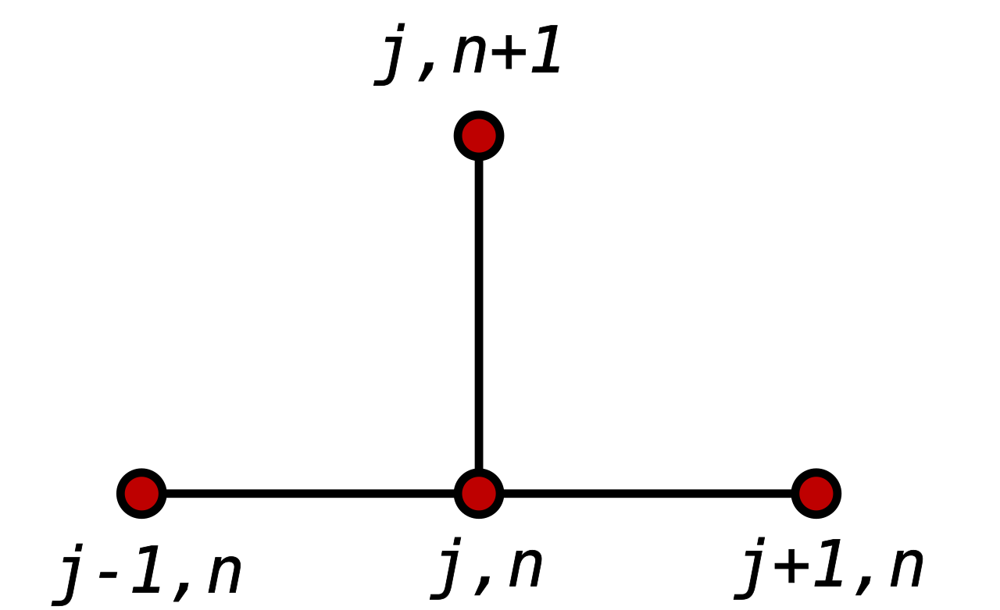
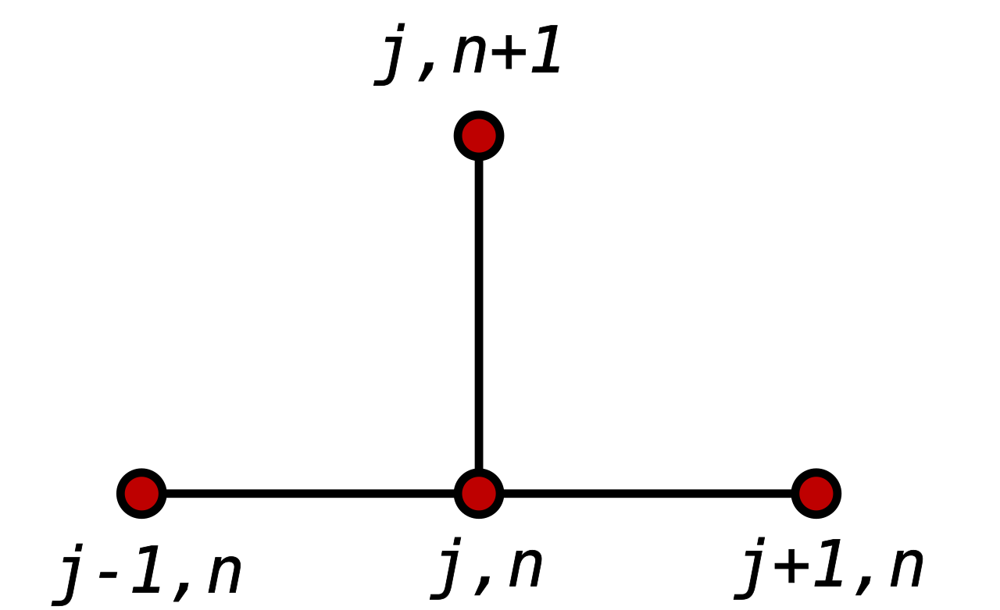
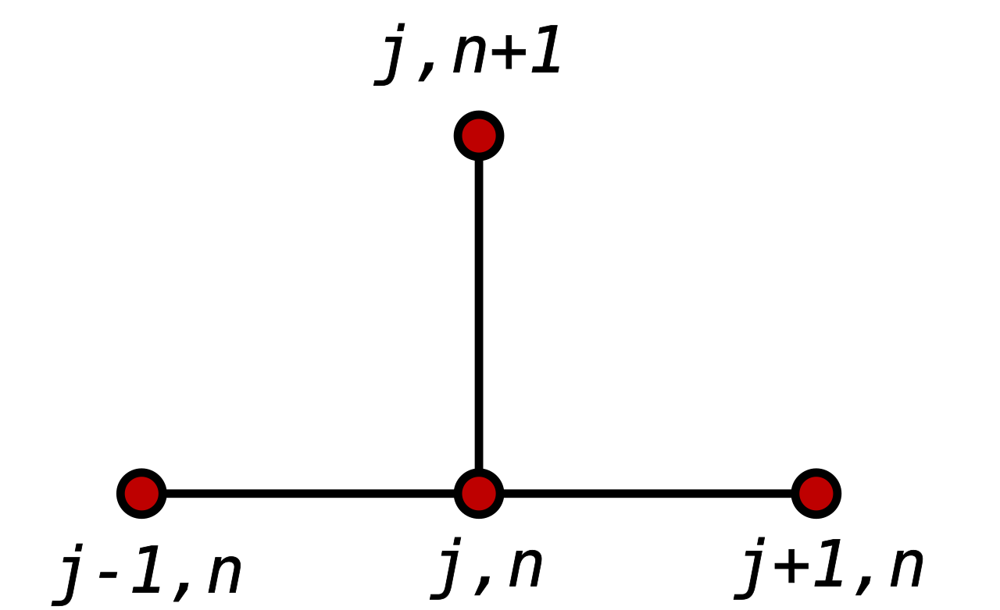

### <span style="color:dodgerblue; "> FTCS discretization 1D diffusion equation </span>
<span style="color:dodgerblue; "> $$\frac{\partial u}{\partial t} = D \frac{\partial^2 u}{\partial x^2}$$ </span>

##### Where _j_ is the space index and _n_ is the time index.
##### Time derivative: Forward difference (first-order accurate in time) 
$$\frac{\partial u}{\partial t}_j^n  \approx \frac{{u_j^{n+1} - u_j^n}} {\Delta t}$$
##### Spatial derivative: Central difference (second-order accurate in space) 
$$\frac{\partial^2 u}{\partial x^2}_j^n  \approx \frac{{u_{j+1}^n - 2u_j^n - u_{j-1}^n}} {(\Delta x)^2}$$
##### Combining the time and spatial derivatives we get the FTCS scheme. _D_ is the diffusion coeficient in ($\frac {m^2}{s}$)
$$\frac{{u_j^{n+1} - u_j^n}} {\Delta t} = D \frac{{u_{j+1}^n - 2u_j^n - u_{j-1}^n}} {(\Delta x)^2}$$
##### $u_{j}^{n+1}$ can be explicitly solved if values of _u_ at previous time step _n_ are known. 
##### $\vartheta$ indicates the order of the error. In this case 2nd order in space and 1st order in time.
$$ u_j^{n+1} =  u_j^n + \frac{D \Delta t}{\Delta x^2}({u_{j+1}^n - 2u_j^n - u_{j-1}^n}) + \vartheta (\Delta x^2 \Delta t )$$ 
##### Lets define the mesh Fourier or diffusion number (_F_) which is stable for 1D when _F_ $\leq$ 0.5. 
$$ F = \frac{D \Delta t}{\Delta x^2}$$
##### If rearange things a bit, we express a finite solution that resolves each node in a matrix.
$$ u_j^{n+1} =  u_j^n + F({u_{j+1}^n - 2u_j^n - u_{j-1}^n}) = F \cdot u_{j+1}^n + (1-2 F)u_j^n + F \cdot u_{j-1}^n$$
#### 5 node example matrices 3 internal nodes and 1 boundary on each end
##### 3 internal nodes
$$
\begin{bmatrix} 
 u_2 \\ u_3 \\ u_4  
\end{bmatrix}^{n+1} = 
\begin{bmatrix} 
F & 1-2F & F & 0 & 0 \\ 
0 & F & 1-2F & F & 0 \\ 
0 & 0 & F & 1-2F & F \\ 
\end{bmatrix} 
\begin{bmatrix} 
u_2 \\ u_3 \\ u_4 
\end{bmatrix}^n
$$

##### Matrix for fixed Dirichlet boundaries - $u_1$ and $u_5$ are constant
$$
\begin{bmatrix} 
u_1 \\ u_2 \\ u_3 \\ u_4 \\ u_5 
\end{bmatrix}^{n+1} = 
\begin{bmatrix} 
1 & 0 & 0 & 0 & 0 \\ 
F & 1-2F & F & 0 & 0 \\ 
0 & F & 1-2F & F & 0 \\ 
0 & 0 & F & 1-2F & F \\ 
0 & 0 & 0 & 0 & 1 
\end{bmatrix} 
\begin{bmatrix} 
u_1 \\ u_2 \\ u_3 \\ u_4 \\ u_5 
\end{bmatrix}^n
$$

##### Matrix for Neumann boundary condition - Insulated boundaries allow Zero-Flux $ \to \frac{\partial u}{\partial x} = 0 $
$$
\begin{bmatrix} 
u_1 \\ u_2 \\ u_3 \\ u_4 \\ u_5 
\end{bmatrix}^{n+1} = 
\begin{bmatrix} 
1-2F & 2F & 0 & 0 & 0 \\ 
F & 1-2F & F & 0 & 0 \\ 
0 & F & 1-2F & F & 0 \\ 
0 & 0 & F & 1-2F & F \\ 
0 & 0 & 0 & 2F & 1-2F 
\end{bmatrix} 
\begin{bmatrix} 
u_1 \\ u_2 \\ u_3 \\ u_4 \\ u_5 
\end{bmatrix}^n
$$

### <span style="color:magenta; ">Code defining matrix with Dirichlet or Neumann boundary </span>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import numpy as np
from numba import njit

# Define the explicit matrix along with the the option to select a Dirichlet or Neumann boundary
@njit
def ftcs_numba(u, F, Nt, Nx, boundary):
    for k in range(Nt - 1):
        for i in range(1, Nx - 1):
            u[i, k+1] = (
                u[i, k] +
                F * (u[i-1, k] - 2*u[i, k] + u[i+1, k])
            )
        if boundary == "Dirichlet":
            # Dirichlet boundaries
            u[0, k+1] = u[0, 0]
            u[-1, k+1] = u[-1, 0]
        elif boundary == "Neumann":
            # Neumann BC: du/dx = 0
            u[0,  k+1] = u[1,  k+1]
            u[-1, k+1] = u[-2, k+1]
    return u

### <span style="color:dodgerblue; "> Courant number (CFL number)   </span>
##### Defining time steps and spatial element sizes such that $ Co \le 1$ insures a stable solution.
$$ Co = u \frac{\Delta t} {\Delta x} $$
##### For 1D we can determine a time step for a stable solution with:
$$ Co \leq 1  \rightarrow  \frac{D \Delta t}{\Delta x^2} \leq \frac{1} {2}   \rightarrow F \leq \frac{1} {2} \rightarrow dt = Co \frac{dx^2} {2D} $$ 
<div align="center">
    <img src="courant_number.png" width="400">
</div> 

### <span style="color:magenta; ">Lets test the limit and blow thing up!! </span>

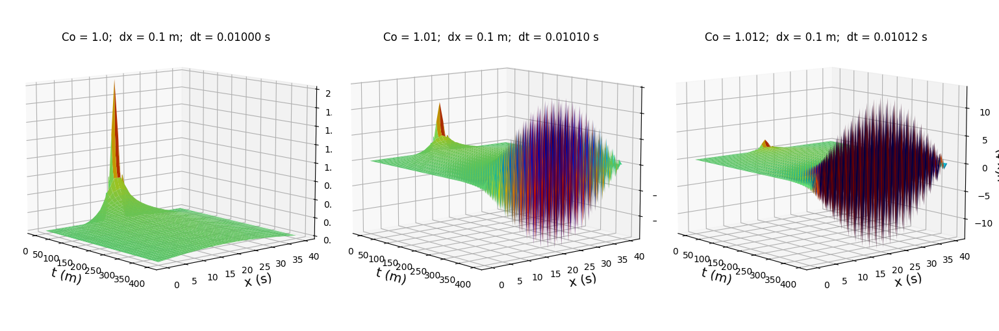

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import colors
# Define Parameters
D = 0.5 # Difusion coefficient (m^2/s)
a, b = 0, 4 # Spatial domain extent (m)
dx = 0.1 # Spatial domain element resolution (m)
x = np.arange(a, b + dx, dx) # Spatial domain

CFLs = [1.0, 1.01, 1.012] # If the Courant > 1 solution blows up
dts = []
u_CFLs = {}
u_keys = ['u0','u1','u3']
i = 0
for Co in CFLs:
    dt = Co * dx**2 / (2 * D) # time step that insures stability
    dts.append(dt)
    tmax = 4 # Simulation duration (s)
    t = np.arange(0, tmax + dt, dt)
    
    F = D * dt / dx**2 # Fourier number
    Nt = len(t)
    Nx = len(x)
    
    source = 1 / (2 * dx * np.sqrt(2 * np.pi)) 
    # Initial condition (vectorized)
    x0 = 2 # Source position
    u0 = (source * np.exp(-(x - x0)**2 / (2 * dx**2)))
    
    # FTCS with Dirichlet boundary
    u = np.zeros((Nx, Nt))
    u[:, 0] = u0
    u_CFLs[u_keys[i]] = ftcs_numba(u, F, Nt, Nx, boundary = "Dirichlet")
    i += 1

fig, axs = plt.subplots(
    1, 3,
    figsize=(15, 6),
    subplot_kw={'projection': '3d'},
    constrained_layout=True
)
i = 0
norm = colors.Normalize(vmin=np.nanmin(u_CFLs['u1']), vmax=np.nanmax(u_CFLs['u1']))

for ax, (key, Z) in zip(axs, u_CFLs.items()):
    Nt, Nx = Z.shape
    X, T = np.meshgrid(np.arange(Nx), np.arange(Nt))
        
    surf = ax.plot_surface(
        X, T, Z,
        facecolors=plt.cm.jet(norm(Z)),
        linewidth=0
    )
    ax.set_xlabel('t (m)', fontsize=14)
    ax.set_ylabel('x (s)', fontsize=14)
    ax.set_zlabel('u(x,t)', fontsize=14, labelpad=1)
    # Rotate 
    ax.view_init(elev=10, azim=-40)

    ax.set_title(f'Co = {CFLs[i]};  dx = {dx} m;  dt = {dts[i]:.5f} s', y = 0.95)
    i += 1

plt.show()

### <span style="color:magenta; ">Compare stable solutions with Dirichlet and Neumann boundary conditions </span>

In [3]:
# Define Parameters
D = 0.5 # Difusion coefficient (m^2/s)
a, b = 0, 4 # Spatial domain extent (m)
dx = 0.1 # Spatial domain element resolution (m)
x = np.arange(a, b + dx, dx) # Spatial domain

Co = 1 # Stable 

dt = Co * dx**2 / (2 * D) # time step that insures stability
tmax = 1 # Simulation duration (s)
t = np.arange(0, tmax + dt, dt)

F = D * dt / dx**2 # Fourier number
Nt = len(t)
Nx = len(x)

source = 1 / (2 * dx * np.sqrt(2 * np.pi)) 
# Initial condition (vectorized)
x0 = 2 # Source position
u0 = (source * np.exp(-(x - x0)**2 / (2 * dx**2)))

# FTCS with Dirichlet boundary
ud = np.zeros((Nx, Nt))
ud[:, 0] = u0
ud = ftcs_numba(ud, F, Nt, Nx, boundary = "Dirichlet")

# FTCS with Neu boundary
un = np.zeros((Nx, Nt))
un[:, 0] = u0
un = ftcs_numba(un, F, Nt, Nx, boundary = "Neumann")

In [5]:
from IPython.display import display, HTML
display(HTML('<img src="diffusion_animation_1d.gif" width="1000">'))

### <span style="color:dodgerblue; "> FTCS discretization 2D diffusion equation </span>
<span style="color:dodgerblue; "> 
    $$\frac{\partial u}{\partial t} = D \left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)$$ 
</span>

##### Lets define the mesh Fourier or diffusion number (_F_) which is stable for 2D when _F_ $\leq$ 0.25. 
$$ F = \frac{D \Delta t}{\Delta x^2}$$

##### If rearange things a bit, we express a finite solution that resolves each node in a matrix.
$$ u_j^{n+1} =  u_j^n + F({u_{j+1}^n - 2u_j^n - u_{j-1}^n}) $$

### <span style="color:dodgerblue; "> Courant number (CFL number)   </span>
##### For 2D we can determine a time step for a stable solution with:
$$ Co \leq 1  \rightarrow  \frac{D \Delta t}{\Delta x^2} + \frac{D \Delta t}{\Delta y^2} \leq \frac{1} {2}   \rightarrow F \leq \frac{1} {4} \rightarrow dt = Co \frac{dx^2} {4D} $$ 

In [5]:
from numba import njit

@njit
def ftcs_numba_2d(u, Fx, Fy, Nt, Nx, Ny, boundary):

    for k in range(Nt - 1):

        # Interior nodes
        for i in range(1, Nx - 1):
            for j in range(1, Ny - 1):

                u[i, j, k+1] = (
                    u[i, j, k]
                    + Fx * (
                        u[i-1, j, k]
                        - 2*u[i, j, k]
                        + u[i+1, j, k]
                    )
                    + Fy * (
                        u[i, j-1, k]
                        - 2*u[i, j, k]
                        + u[i, j+1, k]
                    )
                )

        if boundary == "Dirichlet":

            # left/right
            u[0, :, k+1]  = u[0, :, 0]
            u[-1, :, k+1] = u[-1, :, 0]

            # bottom/top
            u[:, 0, k+1]  = u[:, 0, 0]
            u[:, -1, k+1] = u[:, -1, 0]

        elif boundary == "Neumann":

            # du/dx = 0
            u[0, :, k+1]  = u[1, :, k+1]
            u[-1, :, k+1] = u[-2, :, k+1]

            # du/dy = 0
            u[:, 0, k+1]  = u[:, 1, k+1]
            u[:, -1, k+1] = u[:, -2, k+1]

    return u

In [6]:
a, b = 0, 1
dx = dy = 0.1
D = 0.5

x = np.arange(a, b + dx, dx)
y = np.arange(a, b + dy, dy)
Nx = len(x)
Ny = len(y)
X, Y = np.meshgrid(x, y, indexing='ij')

x0 = b/2
y0 = b/2

sigma = dx
#source = 1/(2*np.pi*sigma**2)
source = 1 / (4 * dx * np.sqrt(2 * np.pi)) 

u0 = source*np.exp(
    -((X-x0)**2 + (Y-y0)**2)/(2*sigma**2)
)

Co = 1

dt = Co * dx**2 / (4 * D)

Fx = D*dt/dx**2
Fy = D*dt/dy**2

Nt = len(t)

ud = np.zeros((Nx, Ny, Nt))
ud[:, :, 0] = u0
ud = ftcs_numba_2d(ud, Fx, Fy, Nt, Nx, Ny, boundary="Dirichlet")

un = np.zeros((Nx, Ny, Nt))
un[:, :, 0] = u0
un = ftcs_numba_2d(un, Fx, Fy, Nt, Nx, Ny, boundary="Neumann")


In [6]:
from IPython.display import display, HTML
display(HTML('<img src="diffusion_animation_2d.gif" width="1000">'))

In [7]:
import matplotlib.animation as animation
from IPython.display import HTML

fig, (ax1, ax2) = plt.subplots(1,2, figsize= (8, 4))

line1, = ax1.plot(x, ud[:, 0], color='c', lw=0.7)
fill1 = ax1.fill_between(x, ud[:, 0], color='c', alpha=0.5)
ax1.set_xlim(a, b)
ax1.set_ylim(0, np.max(ud))
ax1.set_xlabel('x (m)', fontsize=14)
ax1.set_ylabel('u(x,t)', fontsize=14)
ax1.set_title('Dirichlet boundaries')
ax1.grid()

line2, = ax2.plot(x, un[:, 0], color='c', lw=0.7)
fill2 = ax2.fill_between(x, un[:, 0], color='c', alpha=0.5)
ax2.set_xlim(a, b)
ax2.set_ylim(0, np.max(un))
ax2.set_xlabel('x (m)', fontsize=14)
ax2.set_title('Neumann boundaries')
ax2.grid()

def update(frame):
    # Update line
    line1.set_ydata(ud[:, frame])
    line2.set_ydata(un[:, frame])

    # Remove previous fill_between patches
    for coll in ax1.collections:
        coll.remove()
        
    for coll in ax2.collections:
        coll.remove()

    # Draw new filled region
    ax1.fill_between(x, ud[:, frame], color='c', alpha=0.5)
    ax2.fill_between(x, un[:, frame], color='c', alpha=0.5)

    ax1.set_title(f"Dirichlet boundaries at t = {t[frame]:.2f} s")
    ax2.set_title(f"Neumann boundaries at t = {t[frame]:.2f} s")

    return line1, line2

ani = animation.FuncAnimation(
    fig, update, frames=Nt, interval=40, blit=False
)

plt.close(fig)
# Convert the animation to a JSHtml widget and render it
HTML(ani.to_jshtml())

In [8]:
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.animation as animation
from IPython.display import HTML
from matplotlib.colors import LinearSegmentedColormap

white_cyan_darkcyan = LinearSegmentedColormap.from_list(
    "white_cyan_darkcyan",
    ["white", "c","darkcyan"]
)

fig = plt.figure(figsize=(9, 4))

gs = GridSpec(
    1, 3,
    width_ratios=[1, 1, 0.05],  # last column for colorbar
    wspace=0.15
)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
cax = fig.add_subplot(gs[0, 2])

im1 = ax1.imshow(
    ud[:, :, 0].T,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap=white_cyan_darkcyan,
    vmin=0,
    vmax=ud.max(),      # fixed scale over entire simulation
    interpolation='bicubic',
    aspect='equal'
)
title1 = ax1.set_title(f'Dirichlet boundaries at t = {t[0]:.2f} s')
ax1.set_xlabel('x (m)')
ax1.set_ylabel('y (m)')

im2 = ax2.imshow(
    un[:, :, 0].T,
    origin='lower',
    extent=[x.min(), x.max(), y.min(), y.max()],
    cmap=white_cyan_darkcyan,
    vmin=0,
    vmax=un.max(),      # fixed scale over entire simulation
    interpolation='bicubic',
    aspect='equal'
)
title2 = ax2.set_title(f'Neumann boundaries at t = {t[0]:.2f} s')
ax2.set_xlabel('x (m)')
ax2.tick_params(labelleft=False)

cbar = fig.colorbar(im2, cax=cax)
cbar.set_label('Concentration')

def update(frame):
    im1.set_array(ud[:, :, frame].T)
    title1.set_text(f'Dirichlet boundaries at t = {t[frame]:.2f} s')
    im2.set_array(un[:, :, frame].T)
    title2.set_text(f'Neumann boundaries at t = {t[frame]:.2f} s')
    return im1, im2, title1, title2


ani = animation.FuncAnimation(
    fig,
    update,
    frames=Nt,
    interval=40,
    blit=False
)

plt.close(fig)

HTML(ani.to_jshtml())

In [ ]:
# Save as GIF
ani.save(
    "diffusion_2d.gif",
    writer="pillow",
    fps=25
)

plt.close(fig)

# Implicit Scheme - Backward Time, Centered Space Method (BTCS) 
## BTCS method is stable and convergent, but more computationally intensive.

<div align="center">
    <img src="Implicit_method-stencil.png" width="400">
</div> 

# Crank-Nicolson
### Crank Nicolson - Combines Explicit and Impicit Schemes
<div align="center">
    <img src="Crank-Nicolson-stencil.png" width="400">
</div> 